In [6]:
import pandas as pd 
url="https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df= pd.read_csv(url)
df.shape


(891, 12)

In [7]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
df.select_dtypes(include="number").columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

In [10]:
df.select_dtypes(include="object").columns

Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')

In [11]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [14]:
df["Survived"].value_counts()


Survived
0    549
1    342
Name: count, dtype: int64

In [15]:
df["Survived"].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [16]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [21]:
pd.crosstab(df["Sex"],df["Survived"],normalize="index")

Survived,0,1
Sex,,
female,0.257962,0.742038
male,0.811092,0.188908


In [22]:
df["Pclass"].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [25]:
pd.crosstab(df["Pclass"],df["Survived"],normalize="index")

Survived,0,1
Pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363


In [26]:
df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [27]:
df.groupby("Survived")["Age"].mean()

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

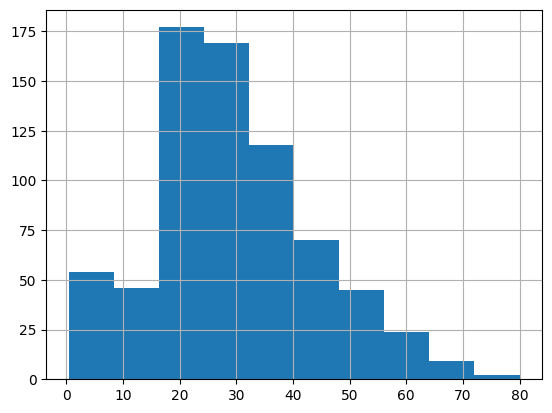

In [30]:
import matplotlib.pyplot as plt
df["Age"].hist()
plt.show()

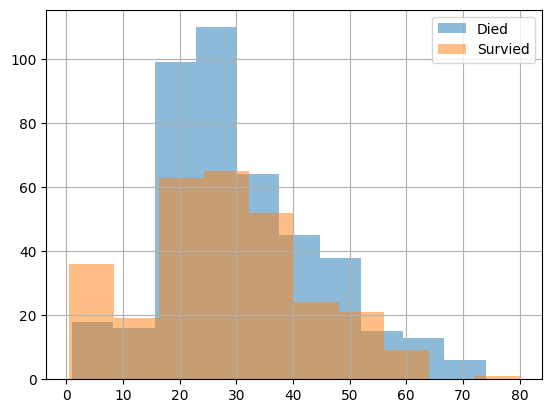

In [34]:
df[df["Survived"]==0]["Age"].hist(alpha=0.5,label="Died")
df[df["Survived"]==1]["Age"].hist(alpha=0.5,label="Survied")
plt.legend()
plt.show()

In [35]:
bins=[0,10,20,30,40,50,100]
df["Agegroup"]=pd.cut(df["Age"],bins=bins)
df["Agegroup"].value_counts().sort_index()


Agegroup
(0, 10]       64
(10, 20]     115
(20, 30]     230
(30, 40]     155
(40, 50]      86
(50, 100]     64
Name: count, dtype: int64

In [36]:
pd.crosstab(df["Agegroup"],df["Survived"],normalize ="index")


Survived,0,1
Agegroup,,
"(0, 10]",0.406250,0.593750
"(10, 20]",0.617391,0.382609
"(20, 30]",0.634783,0.365217
"(30, 40]",0.554839,0.445161
"(40, 50]",0.616279,0.383721
"(50, 100]",0.656250,0.343750


In [37]:
df[df["Age"].isnull()].head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Agegroup
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q,NaN
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S,NaN
19,20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C,NaN
26,27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C,NaN
28,29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q,NaN


In [40]:
df[df["Age"].isnull()]["Survived"].value_counts()

Survived
0    125
1     52
Name: count, dtype: int64

In [42]:
df[df["Age"].notnull()]["Survived"].value_counts()

Survived
0    424
1    290
Name: count, dtype: int64

In [43]:
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [44]:
pd.crosstab(df["Embarked"], df["Survived"])

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [45]:
pd.crosstab(df["Embarked"], df["Survived"], normalize="index")

Survived,0,1
Embarked,,
C,0.446429,0.553571
Q,0.610390,0.389610
S,0.663043,0.336957


In [46]:
pd.crosstab([df["Embarked"], df["Pclass"]], df["Survived"], normalize="index")

Survived                0         1
Embarked Pclass                    
C        1       0.305882  0.694118
         2       0.470588  0.529412
         3       0.621212  0.378788
Q        1       0.500000  0.500000
         2       0.333333  0.666667
         3       0.625000  0.375000
S        1       0.417323  0.582677
         2       0.536585  0.463415
         3       0.810198  0.189802

In [47]:
df["Fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

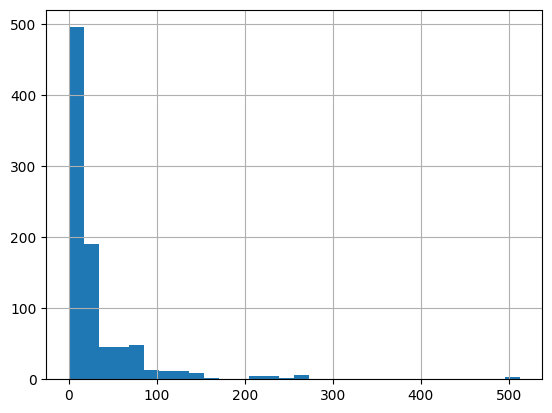

In [48]:
df["Fare"].hist(bins=30)
plt.show()

In [49]:
df.groupby("Survived")["Fare"].mean()

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64

In [50]:
df.groupby("Survived")["Fare"].median()

Survived
0    10.5
1    26.0
Name: Fare, dtype: float64

In [51]:
df.groupby("Survived")["Fare"].describe()

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,549.0,22.117887,31.388207,0.0,7.8542,10.5,26.0,263.0000
1,342.0,48.395408,66.596998,0.0,12.4750,26.0,57.0,512.3292


In [52]:
df.groupby("Pclass")["Fare"].median()

Pclass
1    60.2875
2    14.2500
3     8.0500
Name: Fare, dtype: float64

In [53]:
df.groupby("Pclass")["Fare"].describe()

,count,mean,std,min,25%,50%,75%,max
Pclass,,,,,,,,
1,216.0,84.154687,78.380373,0.0,30.92395,60.2875,93.5,512.3292
2,184.0,20.662183,13.417399,0.0,13.00000,14.2500,26.0,73.5000
3,491.0,13.675550,11.778142,0.0,7.75000,8.0500,15.5,69.5500


In [54]:
df["Fare"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0])

0.50     14.45420
0.75     31.00000
0.90     77.95830
0.95    112.07915
0.99    249.00622
1.00    512.32920
Name: Fare, dtype: float64

In [55]:
df["SibSp"].value_counts().sort_index()

SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

In [56]:
df["Parch"].value_counts().sort_index()

Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

In [57]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [58]:
df["FamilySize"].value_counts().sort_index()

FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

In [59]:
pd.crosstab(
    df["FamilySize"],
    df["Survived"],
    normalize="index"
)

Survived,0,1
FamilySize,,
1,0.696462,0.303538
2,0.447205,0.552795
3,0.421569,0.578431
4,0.275862,0.724138
5,0.800000,0.200000
6,0.863636,0.136364
7,0.666667,0.333333
8,1.000000,0.000000
11,1.000000,0.000000


In [62]:
df["IsAlone"]=(df["FamilySize"]==1).astype(int)


In [64]:
pd.crosstab(df["IsAlone"], df["Survived"],normalize="index")

Survived,0,1
IsAlone,,
0,0.494350,0.505650
1,0.696462,0.303538


In [65]:
df=df.drop(columns=["Agegroup"])

In [66]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'FamilySize',
       'IsAlone'],
      dtype='object')

In [67]:
X=df.drop(columns=["Survived"])
Y=df["Survived"]

In [68]:
X.shape,Y.shape

((891, 13), (891,))

In [71]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [72]:
X_train.shape, X_test.shape

((712, 13), (179, 13))

In [73]:
X_train.dtypes

PassengerId      int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
FamilySize       int64
IsAlone          int64
dtype: object

In [74]:
X_train.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age            137
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          552
Embarked         2
FamilySize       0
IsAlone          0
dtype: int64

In [81]:
X_train=X_train.drop(columns=["Cabin"])

KeyError: "['Cabin'] not found in axis"

In [80]:
X_train.shape

(891, 13)

In [82]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [83]:
X_train.shape, X_test.shape

((712, 13), (179, 13))

In [84]:
X_train = X_train.drop(columns=["Cabin"])
X_test = X_test.drop(columns=["Cabin"])

In [85]:
X_train.shape, X_test.shape

((712, 12), (179, 12))

In [86]:
numeric_features = [
    "Pclass", "Age", "SibSp", "Parch",
    "Fare", "FamilySize", "IsAlone"
]

categorical_features = ["Sex", "Embarked"]

In [87]:
from sklearn.impute import SimpleImputer
numeric_imputer = SimpleImputer(strategy="median")


In [88]:
numeric_imputer.fit(X_train[numeric_features])

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Age','SibSp',...,'Fare','FamilySize','IsAlone']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](7,)","[ 3. ,28.5 , 0. ,...,14.45, 1. , 1. ]"


In [92]:
from sklearn.impute import SimpleImputer

categorical_imputer = SimpleImputer(strategy="most_frequent")

categorical_imputer.fit(X_train[categorical_features])

X_train_cat = categorical_imputer.transform(X_train[categorical_features])
X_test_cat = categorical_imputer.transform(X_test[categorical_features])

In [89]:
X_train_num = numeric_imputer.transform(X_train[numeric_features])
X_test_num = numeric_imputer.transform(X_test[numeric_features])

In [90]:
X_train_num.shape, X_test_num.shape

((712, 7), (179, 7))

In [93]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown="ignore",sparse_output=False)
encoder.fit(X_train_cat)
X_train_cat_encoded = encoder.transform(X_train_cat)
X_test_cat_encoded = encoder.transform(X_test_cat)

In [94]:
X_train_cat_encoded.shape, X_test_cat_encoded.shape

((712, 5), (179, 5))

In [95]:
from sklearn.pipeline import  Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler",StandardScaler())
])

In [96]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [97]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer([("num",numeric_pipeline, numeric_features),("cat", categorical_pipeline,categorical_features)
])

In [99]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [100]:
preprocessor.fit_transform(X_test)

array([[ 0.81887886, -0.3658317 ,  1.08714223, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.81887886,  1.17541866, -0.51449118, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.81887886, -0.51995674, -0.51449118, ...,  1.        ,
         0.        ,  0.        ],
       ...,
       [-0.3632124 , -0.05758163, -0.51449118, ...,  0.        ,
         0.        ,  1.        ],
       [-0.3632124 , -0.44289422, -0.51449118, ...,  1.        ,
         0.        ,  0.        ],
       [-0.3632124 ,  0.17360592,  0.28632553, ...,  0.        ,
         0.        ,  1.        ]], shape=(179, 12))

In [101]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train_processed,y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [104]:
y_pred=model.predict(X_test_processed)


In [105]:
y_pred[:20]

array([0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1])

In [106]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8044692737430168


In [107]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[97 13]
 [22 47]]


In [108]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [114]:
from sklearn.dummy import DummyClassifier 
from sklearn.metrics import accuracy_score
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train,y_train)
dummy_pred=dummy.predict(X_test)
print("Baseline accuracy:",accuracy_score(y_test,dummy_pred))

Baseline accuracy: 0.6145251396648045


In [115]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
full_model = Pipeline([
    ("preprocessor",preprocessor),
    ("model",LogisticRegression(max_iter=1000))
])
full_model.fit(X_train,y_train)
y_pred_pipeline = full_model.predict(X_test)
print("Accuracy:",accuracy_score(y_test,y_pred_pipeline))


Accuracy: 0.8044692737430168


In [116]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("Decision Tree accuracy:", accuracy_score(y_test, tree_pred))

Decision Tree accuracy: 0.7932960893854749


In [117]:
print("Training accuracy:", tree_model.score(X_train, y_train))
print("Test accuracy:", tree_model.score(X_test, y_test))

Training accuracy: 0.9831460674157303
Test accuracy: 0.7932960893854749


In [118]:
for depth in [2, 3, 4, 5, 6, 8, 10]:
    
    tree_model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])
    
    tree_model.fit(X_train, y_train)
    
    train_acc = tree_model.score(X_train, y_train)
    test_acc = tree_model.score(X_test, y_test)
    
    print(
        f"Depth {depth}: "
        f"Train = {train_acc:.3f}, "
        f"Test = {test_acc:.3f}"
    )

Depth 2: Train = 0.805, Test = 0.760
Depth 3: Train = 0.829, Test = 0.804
Depth 4: Train = 0.838, Test = 0.793
Depth 5: Train = 0.864, Test = 0.765
Depth 6: Train = 0.878, Test = 0.782
Depth 8: Train = 0.910, Test = 0.777
Depth 10: Train = 0.930, Test = 0.777


In [119]:
from sklearn.metrics import f1_score

for depth in [2, 3, 4, 5, 6, 8, 10]:
    
    tree_model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])
    
    tree_model.fit(X_train, y_train)
    
    train_acc = tree_model.score(X_train, y_train)
    test_acc = tree_model.score(X_test, y_test)
    
    test_pred = tree_model.predict(X_test)
    test_f1 = f1_score(y_test, test_pred)
    
    print(
        f"Depth {depth}: "
        f"Train Acc = {train_acc:.3f}, "
        f"Test Acc = {test_acc:.3f}, "
        f"Test F1 = {test_f1:.3f}"
    )

Depth 2: Train Acc = 0.805, Test Acc = 0.760, Test F1 = 0.590
Depth 3: Train Acc = 0.829, Test Acc = 0.804, Test F1 = 0.720
Depth 4: Train Acc = 0.838, Test Acc = 0.793, Test F1 = 0.673
Depth 5: Train Acc = 0.864, Test Acc = 0.765, Test F1 = 0.656
Depth 6: Train Acc = 0.878, Test Acc = 0.782, Test F1 = 0.672
Depth 8: Train Acc = 0.910, Test Acc = 0.777, Test F1 = 0.672
Depth 10: Train Acc = 0.930, Test Acc = 0.777, Test F1 = 0.688


In [120]:
from sklearn.metrics import f1_score

logistic_f1 = f1_score(y_test, y_pred)

print("Logistic Regression F1:", logistic_f1)

Logistic Regression F1: 0.7286821705426356


In [121]:
from sklearn.model_selection import cross_val_score

logistic_cv = cross_val_score(
    full_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

tree_depth3 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

tree_cv = cross_val_score(
    tree_depth3,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Logistic Regression F1 scores:", logistic_cv)
print("Logistic Regression mean F1:", logistic_cv.mean())

print()

print("Decision Tree F1 scores:", tree_cv)
print("Decision Tree mean F1:", tree_cv.mean())

Logistic Regression F1 scores: [0.7079646  0.64583333 0.76363636 0.75       0.74766355]
Logistic Regression mean F1: 0.7230195700282955

Decision Tree F1 scores: [0.74285714 0.59090909 0.77777778 0.76923077 0.72340426]
Decision Tree mean F1: 0.7208358072187859


In [124]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    "model__max_depth": [2, 3, 4, 5, 6, 8, 10]
}
tree_search = GridSearchCV(
    estimator=tree_depth3,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)
tree_search.fit(X_train, y_train)
print("Best parameters:", tree_search.best_params_)
print("Best CV F1:", tree_search.best_score_)


Best parameters: {'model__max_depth': 6}
Best CV F1: 0.7329106321370807


In [126]:
best_tree=tree_search.best_estimator_
best_tree_pred = best_tree.predict(X_test)
print("Test acuracy :", accuracy_score(y_test,best_tree_pred))
print ("Test F1 :", f1_score(y_test, best_tree_pred))


Test acuracy : 0.7821229050279329
Test F1 : 0.6722689075630253


In [132]:
from sklearn.ensemble import RandomForestClassifier
forest_model =Pipeline ([
    ("preprocessor",preprocessor),
    ("model",RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])
forest_model.fit(X_train,y_train)
forest_pred = forest_model.predict(X_test)
print("Test acuracy :", accuracy_score(y_test,forest_pred))
print ("Test F1 :", f1_score(y_test, forest_pred))

Test acuracy : 0.8156424581005587
Test F1 : 0.7441860465116279


In [133]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

for n in [10, 50, 100, 200, 400]:

    forest = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=n,
            random_state=42
        ))
    ])

    forest.fit(X_train, y_train)
    pred = forest.predict(X_test)

    print(
        f"Trees={n:3d} | "
        f"Accuracy={accuracy_score(y_test, pred):.3f} | "
        f"F1={f1_score(y_test, pred):.3f}"
    )

Trees= 10 | Accuracy=0.793 | F1=0.722
Trees= 50 | Accuracy=0.804 | F1=0.737
Trees=100 | Accuracy=0.810 | F1=0.738
Trees=200 | Accuracy=0.816 | F1=0.744
Trees=400 | Accuracy=0.804 | F1=0.733


In [139]:
best_forest = forest_model.named_steps["model"]
feature_names = (
     numeric_features+ list (
         forest_model.named_steps["preprocessor"]
         .named_transformers_["cat"]
         .named_steps["encoder"]
         .get_feature_names_out(categorical_features)
     )
)
import pandas as pd
importance = pd.Series(
    best_forest.feature_importances_,
    index=feature_names
).sort_values(ascending = False)
print(importance)


Fare          0.252940
Age           0.235547
Sex_male      0.143562
Sex_female    0.142013
Pclass        0.084500
FamilySize    0.045822
SibSp         0.025237
Parch         0.023833
Embarked_S    0.016082
IsAlone       0.012404
Embarked_C    0.011735
Embarked_Q    0.006325
dtype: float64


In [140]:
from sklearn.inspection import permutation_importance
import pandas as pd

result = permutation_importance(
    forest_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42
)

permutation_scores = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print(permutation_scores)

Sex            0.259904
Age            0.075284
Fare           0.067480
Pclass         0.055165
Embarked       0.029367
Parch          0.018631
FamilySize     0.015220
IsAlone        0.001762
Name           0.000000
PassengerId    0.000000
Ticket         0.000000
SibSp         -0.000728
dtype: float64


In [141]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import cross_val_score
boost_model = Pipeline ([
    ("preprocessor",preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])
# Evaluate using cross-validation on training data
boost_cv = cross_val_score(
    boost_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("CV F1 scores:", boost_cv)
print("Mean CV F1:", boost_cv.mean())

CV F1 scores: [0.69306931 0.63829787 0.83018868 0.75728155 0.78431373]
Mean CV F1: 0.7406302274809312


In [142]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

boost_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__learning_rate": [0.03, 0.1, 0.2],
    "model__max_depth": [2, 3]
}

boost_search = GridSearchCV(
    estimator=boost_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

boost_search.fit(X_train, y_train)

print("Best parameters:", boost_search.best_params_)
print("Best CV F1:", boost_search.best_score_)

Best parameters: {'model__learning_rate': 0.2, 'model__max_depth': 2, 'model__n_estimators': 200}
Best CV F1: 0.7595273805393632


In [143]:

from sklearn.model_selection import cross_val_score

forest_cv = cross_val_score(
    forest_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Fold F1 scores:", forest_cv)
print("Mean CV F1:", forest_cv.mean())
print("Std CV F1:", forest_cv.std())

Fold F1 scores: [0.69158879 0.61682243 0.75229358 0.80733945 0.74766355]
Mean CV F1: 0.7231415587756153
Std CV F1: 0.06455972095510268


In [144]:
%pip install xgboost


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [146]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_cv = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Fold F1 scores:", xgb_cv)
print("Mean CV F1:", xgb_cv.mean())
print("Std CV F1:", xgb_cv.std())

Fold F1 scores: [0.71287129 0.65957447 0.81481481 0.76       0.7961165 ]
Mean CV F1: 0.7486754149766006
Std CV F1: 0.05652298250023725


In [147]:

from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

print("Best parameters:", xgb_search.best_params_)
print("Best CV F1:", xgb_search.best_score_)

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300}
Best CV F1: 0.751485136355581


In [148]:

from sklearn.metrics import accuracy_score, f1_score, classification_report

# Best tuned models from cross-validation
best_xgb = xgb_search.best_estimator_
best_boost = boost_search.best_estimator_

models = {
    "Tuned XGBoost": best_xgb,
    "Tuned Gradient Boosting": best_boost,
    "Random Forest": forest_model,
    "Logistic Regression": full_model
}

for name, model in models.items():
    pred = model.predict(X_test)
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_test, pred), 3))
    print("F1:", round(f1_score(y_test, pred), 3))


Tuned XGBoost
Accuracy: 0.782
F1: 0.688

Tuned Gradient Boosting
Accuracy: 0.799
F1: 0.71

Random Forest
Accuracy: 0.816
F1: 0.744

Logistic Regression
Accuracy: 0.804
F1: 0.729


In [149]:
from sklearn.metrics import precision_score,recall_score,f1_score
probs = forest_model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (probs >= threshold).astype(int)

    print(
        f"Threshold={threshold:.1f} | "
        f"Precision={precision_score(y_test, pred):.3f} | "
        f"Recall={recall_score(y_test, pred):.3f} | "
        f"F1={f1_score(y_test, pred):.3f}"
    )

Threshold=0.3 | Precision=0.604 | Recall=0.797 | F1=0.688
Threshold=0.4 | Precision=0.692 | Recall=0.783 | F1=0.735
Threshold=0.5 | Precision=0.787 | Recall=0.696 | F1=0.738
Threshold=0.6 | Precision=0.821 | Recall=0.667 | F1=0.736
Threshold=0.7 | Precision=0.870 | Recall=0.580 | F1=0.696


In [150]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score

weighted_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

weighted_model.fit(X_train, y_train)
weighted_pred = weighted_model.predict(X_test)

print("Precision:", precision_score(y_test, weighted_pred))
print("Recall:", recall_score(y_test, weighted_pred))
print("F1:", f1_score(y_test, weighted_pred))

Precision: 0.7222222222222222
Recall: 0.7536231884057971
F1: 0.7375886524822695


In [152]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score,recall_score,f1_score

weighted_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

weighted_model.fit(X_train, y_train)
weighted_pred = weighted_model.predict(X_test)

print("Precision:", precision_score(y_test, weighted_pred))
print("Recall:", recall_score(y_test, weighted_pred))
print("F1:", f1_score(y_test, weighted_pred))

Precision: 0.7222222222222222
Recall: 0.7536231884057971
F1: 0.7375886524822695


In [153]:
import joblib
joblib.dump(forest_model,"titanic+model.joblib")
print ("Model saved")

Model saved


In [154]:
loaded_model = joblib.load("titanic_model.joblib")

predictions = loaded_model.predict(X_test)
print("Loaded model F1:", f1_score(y_test, predictions))

FileNotFoundError: [Errno 2] No such file or directory: 'titanic_model.joblib'

In [155]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())

Current directory: c:\Users\User\OneDrive\Documents\BTP-PNSR
Files here: ['angle_gather.ipynb', 'cdpgathers_142-200.sgy', 'cdpgathers_2-80.sgy', 'cdpgathers_202-290.sgy', 'cdpgathers_290-310.sgy', 'cdpgathers_601-630.sgy', 'cdpgathers_82-140.sgy', 'titanic+model.joblib', 'velocity_model_derived.csv']


In [156]:
import joblib
import os

save_path = os.path.join(os.getcwd(), "titanic_model.joblib")
joblib.dump(forest_model, save_path)

print("Saved to:", save_path)

Saved to: c:\Users\User\OneDrive\Documents\BTP-PNSR\titanic_model.joblib


In [157]:
loaded_model = joblib.load(save_path)

predictions = loaded_model.predict(X_test)
print("Model loaded successfully!")

Model loaded successfully!


In [158]:
passenger = X_test.iloc[[0]]
prediction = loaded_model.predict(passenger)[0]
probability = loaded_model.predict_proba(passenger)[0][1]
print("Predicted class:", prediction)
print("Survival probability:", round(probability, 3))

Predicted class: 0
Survival probability: 0.155


In [161]:
def predict_survival(passenger,model):
    prediction = loaded_model.predict(passenger)[0]
    probability = loaded_model.predict_proba(passenger)[0][1]
    return {
        "prediction": "Survived" if prediction == 1 else "Did not survive",
        "survival_probability":round (float(probability),3)
    }
result =  predict_survival(X_test.iloc[[0]],loaded_model)
print(result)

{'prediction': 'Did not survive', 'survival_probability': 0.155}


In [169]:

from fastapi import FastAPI
from pydantic import BaseModel
import pandas as pd
import joblib

# Create the API application
app = FastAPI(title="Titanic Survival Predictor")

# Load the trained ML pipeline
model = joblib.load("titanic_model.joblib")


# Define the structure of incoming data
class Passenger(BaseModel):
    Pclass: int
    Sex: str
    Age: float | None = None
    SibSp: int = 0
    Parch: int = 0
    Fare: float
    Embarked: str | None = None
    FamilySize: int
    IsAlone: int


# Create a prediction endpoint
@app.post("/predict")
def predict(passenger: Passenger):
    data = pd.DataFrame([passenger.model_dump()])

    prediction = int(model.predict(data)[0])
    probability = float(model.predict_proba(data)[0][1])

    return {
        "prediction": "Survived" if prediction == 1 else "Did not survive",
        "survival_probability": round(probability, 3)
    }

In [170]:
from fastapi import FastAPI
from pydantic import BaseModel
import pandas as pd
import joblib

app = FastAPI(title="Titanic Survival Predictor")

# Load our trained ML pipeline
model = joblib.load("titanic_model.joblib")


class Passenger(BaseModel):
    Pclass: int
    Sex: str
    Age: float | None = None
    SibSp: int = 0
    Parch: int = 0
    Fare: float
    Embarked: str | None = None
    FamilySize: int
    IsAlone: int


@app.get("/")
def home():
    return {"message": "Titanic Survival Predictor API is running"}


@app.post("/predict")
def predict(passenger: Passenger):
    data = pd.DataFrame([passenger.model_dump()])

    prediction = int(model.predict(data)[0])
    probability = float(model.predict_proba(data)[0][1])

    return {
        "prediction": "Survived" if prediction == 1 else "Did not survive",
        "survival_probability": round(probability, 3)
    }

In [171]:
from sklearn.model_selection import cross_val_score

logistic_scores = cross_val_score(
    full_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

forest_scores = cross_val_score(
    forest_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Logistic Regression:", logistic_scores)
print("Mean Logistic F1:", logistic_scores.mean())

print("Random Forest:", forest_scores)
print("Mean Random Forest F1:", forest_scores.mean())

Logistic Regression: [0.7079646  0.64583333 0.76363636 0.75       0.74766355]
Mean Logistic F1: 0.7230195700282955
Random Forest: [0.69158879 0.61682243 0.75229358 0.80733945 0.74766355]
Mean Random Forest F1: 0.7231415587756153


In [1]:
df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")

print(df["Title"].value_counts())

NameError: name 'df' is not defined

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print(df.shape)
print(df.columns.tolist())

(891, 12)
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [3]:
df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")

print(df["Title"].value_counts().head(5))

Title
Mr        517
Miss      182
Mrs       125
Master     40
Dr          7
Name: count, dtype: int64


In [4]:
print(
    df.groupby("Title")["Survived"]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
      .round(3)
)

              count   mean
Title                     
Lady              1  1.000
Ms                1  1.000
Sir               1  1.000
Mme               1  1.000
the Countess      1  1.000
Mlle              2  1.000
Mrs             125  0.792
Miss            182  0.698
Master           40  0.575
Major             2  0.500
Col               2  0.500
Dr                7  0.429
Mr              517  0.157
Capt              1  0.000
Jonkheer          1  0.000
Don               1  0.000
Rev               6  0.000


In [5]:
title_counts = df["Title"].value_counts()

df["Title_Grouped"] = df["Title"].where(
    df["Title"].map(title_counts) >= 10,
    "Other"
)

print(df["Title_Grouped"].value_counts())

Title_Grouped
Mr        517
Miss      182
Mrs       125
Master     40
Other      27
Name: count, dtype: int64


In [6]:
print(
    df.groupby("Title_Grouped")["Survived"]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
      .round(3)
)

               count   mean
Title_Grouped              
Mrs              125  0.792
Miss             182  0.698
Master            40  0.575
Other             27  0.444
Mr               517  0.157


In [7]:
import pandas as pd
import numpy as np

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

X = df.drop(columns="Survived").copy()
y = df["Survived"]

def extract_title(names):
    return names.str.extract(r",\s*([^.]*)\.")[0].str.strip()

X["Title"] = extract_title(X["Name"])

X["FamilySize"] = X["SibSp"] + X["Parch"] + 1
X["IsAlone"] = (X["FamilySize"] == 1).astype(int)

X = X.drop(columns=["Name", "Ticket", "Cabin", "PassengerId"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = [
    "Pclass", "Age", "SibSp", "Parch",
    "Fare", "FamilySize", "IsAlone"
]
categorical_features = ["Sex", "Embarked", "Title"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

forest_with_title = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=42
    ))
])

scores = cross_val_score(
    forest_with_title,
    X_train, y_train,
    cv=5, scoring="f1"
)

print("F1 scores:", scores)
print("Mean CV F1:", scores.mean())

F1 scores: [0.69724771 0.62385321 0.77477477 0.80769231 0.73076923]
Mean CV F1: 0.7268674461335012


In [8]:
# Baseline: same features, excluding Title
X_train_base = X_train.drop(columns=["Title"])

base_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["Sex", "Embarked"])
])

forest_base = Pipeline([
    ("preprocessor", base_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=42
    ))
])

base_scores = cross_val_score(
    forest_base, X_train_base, y_train,
    cv=5, scoring="f1"
)

print("Without Title:", base_scores)
print("Mean:", base_scores.mean())

print("With Title:", scores)
print("Mean:", scores.mean())

Without Title: [0.69158879 0.61682243 0.75229358 0.80733945 0.74766355]
Mean: 0.7231415587756153
With Title: [0.69724771 0.62385321 0.77477477 0.80769231 0.73076923]
Mean: 0.7268674461335012


In [9]:
experiment_results = pd.DataFrame([
    {
        "experiment": "Random Forest baseline",
        "feature_change": "No Title",
        "mean_cv_f1": base_scores.mean()
    },
    {
        "experiment": "Random Forest + Title",
        "feature_change": "Extracted Title from Name",
        "mean_cv_f1": scores.mean()
    }
])

experiment_results["mean_cv_f1"] = experiment_results["mean_cv_f1"].round(4)

print(experiment_results)

               experiment             feature_change  mean_cv_f1
0  Random Forest baseline                   No Title      0.7231
1   Random Forest + Title  Extracted Title from Name      0.7269


In [10]:
experiment_results.to_csv("experiment_results.csv", index=False)

In [12]:
import mlflow
import mlflow.sklearn
from sklearn.model_selection import cross_val_score
mlflow.set_experiment("Titanic-Survival")
with mlflow.start_run(run_name="RandomForest-Blow.setaseline"):
    model_params=forest_base.named_steps["model"].get_params()
    scores = cross_val_score(
        forest_base,
        X_train_base,
        y_train,
        cv=5,
        scoring="f1"

    )
    mlflow.log_param("model", "RandomForestClassifier")
mlflow.log_param("n_estimators", model_params["n_estimators"])
mlflow.log_param("max_depth", model_params["max_depth"])
mlflow.log_param("cv_folds", 5)
mlflow.log_metric("mean_cv_f1", scores.mean())
mlflow.log_metric("std_cv_f1", scores.std())

print("Mean CV F1:", scores.mean())
print("Std CV F1:", scores.std())

2026/10/10 19:16:03 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/10 19:16:03 INFO mlflow.store.db.utils: Updating database tables
2026/10/10 19:16:06 INFO mlflow.tracking.fluent: Experiment with name 'Titanic-Survival' does not exist. Creating a new experiment.


Mean CV F1: 0.7231415587756153
Std CV F1: 0.06455972095510268


In [14]:
import mlflow
import mlflow.sklearn
from sklearn.model_selection import cross_val_score

mlflow.set_experiment("Titanic-Survival")

with mlflow.start_run(run_name="RandomForest-Baseline"):
    scores_base = cross_val_score(
        forest_base,
        X_train_base,
        y_train,
        cv=5,
        scoring="f1"
    )

    mlflow.log_param("model", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("features", "without_Title")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric("mean_cv_f1", scores_base.mean())
    mlflow.log_metric("std_cv_f1", scores_base.std())

    print("Baseline mean F1:", scores_base.mean())
    print("Baseline std F1:", scores_base.std())

Exception: Run with UUID f4b1e7cd882742d18438ea38d499a208 is already active. To start a new run, first end the current run with mlflow.end_run(). To start a nested run, call start_run with nested=True

In [15]:
import mlflow

mlflow.end_run()
print("Active MLflow run closed.")

Active MLflow run closed.


In [16]:
import mlflow
import mlflow.sklearn
from sklearn.model_selection import cross_val_score

mlflow.set_experiment("Titanic-Survival")

with mlflow.start_run(run_name="RandomForest-Baseline"):
    scores_base = cross_val_score(
        forest_base,
        X_train_base,
        y_train,
        cv=5,
        scoring="f1"
    )

    mlflow.log_param("model", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("features", "without_Title")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric("mean_cv_f1", scores_base.mean())
    mlflow.log_metric("std_cv_f1", scores_base.std())

    print("Baseline mean F1:", scores_base.mean())
    print("Baseline std F1:", scores_base.std())

Baseline mean F1: 0.7231415587756153
Baseline std F1: 0.06455972095510268


In [17]:
with mlflow.start_run(run_name="RandomForest-With-Title"):
    scores_title = cross_val_score(
        forest_with_title,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    mlflow.log_param("model", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("features", "with_Title")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric("mean_cv_f1", scores_title.mean())
    mlflow.log_metric("std_cv_f1", scores_title.std())

    print("With Title mean F1:", scores_title.mean())
    print("With Title std F1:", scores_title.std())

With Title mean F1: 0.7268674461335012
With Title std F1: 0.06376873203336088


In [20]:
import mlflow
import mlflow.sklearn

with mlflow.start_run(run_name="RandomForest-Saved-Model"):
    forest_base.fit(X_train_base, y_train)

    mlflow.sklearn.log_model(
        sk_model=forest_base,
        name="random_forest_model"
    )

    print("Trained model logged to MLflow.")

MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype', 'sklearn.tree._tree.Tree'].

- sklearn.tree._tree.Tree: sklearn.tree._tree.Tree (the shared node storage for DecisionTree*, RandomForest*, ExtraTrees*, and GradientBoosting* models) stores raw node indices (left_child, right_child, feature) that scikit-learn indexes into without bounds checking. A malicious file can set these to out-of-range values: skops loads the object successfully, but calling .predict() on it can then crash the process (segfault) or read out-of-bounds memory. If you created the file yourself or otherwise fully trust its source, you can load it with trusted=["sklearn.tree._tree.Tree"].

Only add the specific types you have reviewed and trust to the `trusted` argument; avoid passing 

In [21]:
import mlflow
import mlflow.sklearn

# Close any run left active by the failed attempt
mlflow.end_run()

with mlflow.start_run(run_name="RandomForest-Saved-Model"):
    forest_base.fit(X_train_base, y_train)

    mlflow.sklearn.log_model(
        sk_model=forest_base,
        name="random_forest_model",
        serialization_format="pickle"
    )

    print("Trained model logged to MLflow.")

2026/10/10 21:21:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Trained model logged to MLflow.


In [22]:
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

mlflow.set_experiment("Titanic-Survival")

with mlflow.start_run(run_name="RandomForest-Saved-Model") as run:
    forest_base.fit(X_train_base, y_train)

    model_info = mlflow.sklearn.log_model(
        sk_model=forest_base,
        name="random_forest_model",
        serialization_format="pickle"
    )

    run_id = run.info.run_id
    print("Run ID:", run_id)
    print("Model URI:", model_info.model_uri)

client = MlflowClient()
print("Logged artifacts:", client.list_artifacts(run_id))

2026/10/10 21:27:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Run ID: ac91369095004fc18698c34a7569a622
Model URI: models:/m-3ee548d46bf14005b22e822d8a26636c
Logged artifacts: []


In [23]:
import mlflow

model_uri = "models:/m-3ee548d46bf14005b22e822d8a26636c"

print(mlflow.artifacts.list_artifacts(artifact_uri=model_uri))

[<FileInfo: file_size=741, is_dir=False, path='MLmodel'>, <FileInfo: file_size=218, is_dir=False, path='conda.yaml'>, <FileInfo: file_size=4736968, is_dir=False, path='model.pkl'>, <FileInfo: file_size=120, is_dir=False, path='python_env.yaml'>, <FileInfo: file_size=89, is_dir=False, path='requirements.txt'>]


In [24]:
loaded_model = mlflow.sklearn.load_model(
    "models:/m-3ee548d46bf14005b22e822d8a26636c"
)

predictions = loaded_model.predict(X_test)

print(predictions[:10])

[0 0 0 0 1 0 1 1 1 0]


In [25]:
from sklearn.metrics import accuracy_score, f1_score

predictions = loaded_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("F1 score:", f1_score(y_test, predictions))

Accuracy: 0.8156424581005587
F1 score: 0.7441860465116279


In [26]:
import mlflow
from sklearn.metrics import accuracy_score, f1_score

# Generate test-set predictions
test_predictions = forest_base.predict(X_test)

# Calculate metrics
test_accuracy = accuracy_score(y_test, test_predictions)
test_f1 = f1_score(y_test, test_predictions)
with mlflow.start_run(run_name="RandomForest-Baseline-Evaluation"):
    mlflow.log_param("model","RandomForest")
    mlflow.log_param("n_estimators",200)
    mlflow.log_param("evaluation_set", "test")

    mlflow.log_metric("test_accuracy", test_accuracy)
    mlflow.log_metric("test_f1", test_f1)

print("Test accuracy:", test_accuracy)
print("Test F1:", test_f1)
                     

Test accuracy: 0.8156424581005587
Test F1: 0.7441860465116279


In [44]:
import mlflow
import mlflow.sklearn
import numpy as np
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, f1_score

def run_experiment(model, model_name, X_train, y_train, X_test, y_test):
    with mlflow.start_run(run_name=model_name):
        print(f"Running experiment: {model_name}")

        # Log model parameters
        mlflow.log_param("model", model_name)
        mlflow.log_param("cv_folds", 5)
        model_params=model.named_steps["model"].get_params()
        mlflow.log_params({
            "n_estimators": model_params["n_estimators"],
            "max_depth": model_params["max_depth"],
            "min_samples_split": model_params["min_samples_split"],
            "min_samples_leaf": model_params["min_samples_leaf"]
        })

        # Train the model
        model.fit(X_train, y_train)
        print("Model training complete!")

        # Cross-validation
        cv_scores = cross_val_score(
            model, X_train, y_train, cv=5, scoring="f1"
        )

        mean_cv_f1 = cv_scores.mean()
        std_cv_f1 = cv_scores.std()

        # Test-set evaluation
        test_predictions = model.predict(X_test)
        test_accuracy = accuracy_score(y_test, test_predictions)
        test_f1 = f1_score(y_test, test_predictions)

        # Log metrics
        mlflow.log_metric("mean_cv_f1", mean_cv_f1)
        mlflow.log_metric("std_cv_f1", std_cv_f1)
        mlflow.log_metric("test_accuracy", test_accuracy)
        mlflow.log_metric("test_f1", test_f1)

        # Log the trained pipeline
        mlflow.sklearn.log_model(
            sk_model=model,
            name="model",
            serialization_format="pickle"
        )

        print("Mean CV F1:", mean_cv_f1)
        print("Std CV F1:", std_cv_f1)
        print("Test accuracy:", test_accuracy)
        print("Test F1:", test_f1)
        print("MLflow run ID:", mlflow.active_run().info.run_id)
run_experiment(
    model=forest_base,
    model_name="RandomForest-Hyperparams",
    X_train=X_train_base,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test
)


Running experiment: RandomForest-Hyperparams
Model training complete!


2026/10/11 01:31:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7231415587756153
Std CV F1: 0.06455972095510268
Test accuracy: 0.8156424581005587
Test F1: 0.7441860465116279
MLflow run ID: bcbec87c3e334288a36813a3f9417ff7


In [42]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

run = client.get_run("7ec52e66562741fe8b53ae6389cfc057")

print("Run name:", run.info.run_name)
print("Experiment ID:", run.info.experiment_id)
print("Status:", run.info.status)
print("Metrics:", run.data.metrics)

Run name: RandomForest-Baseline-Complete
Experiment ID: 1
Status: FINISHED
Metrics: {'mean_cv_f1': 0.7231415587756153, 'std_cv_f1': 0.06455972095510268, 'test_accuracy': 0.8156424581005587, 'test_f1': 0.7441860465116279}


In [43]:
model_params = forest_base.named_steps["model"].get_params()
print("Number of trees:",model_params["n_estimators"])
print("Max depth : ",model_params["max_depth"])
                                  

Number of trees: 200
Max depth :  None


In [45]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

experiment = client.get_experiment_by_name("Titanic-Survival")

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    max_results=10,
    order_by=["attributes.start_time DESC"]
)

for run in runs:
    print(
        run.info.run_name,
        "| Status:", run.info.status,
        "| Run ID:", run.info.run_id
    )

RandomForest-Hyperparams | Status: FINISHED | Run ID: bcbec87c3e334288a36813a3f9417ff7
RandomForest-Hyperparams | Status: FINISHED | Run ID: aad7121978184c6f8332333de0d9cc83
RandomForest-Baseline-Complete | Status: FINISHED | Run ID: 7ec52e66562741fe8b53ae6389cfc057
RandomForest-Baseline | Status: FINISHED | Run ID: 5dfaaebfd6bb40e3b88def6cfab88375
RandomForest-Baseline-Evaluation | Status: FINISHED | Run ID: c5b6ec7fa73d46e897e47a50488e5a22
RandomForest-Saved-Model | Status: FINISHED | Run ID: ac91369095004fc18698c34a7569a622
RandomForest-Saved-Model | Status: FINISHED | Run ID: 0146567de730469faf6c7097db7ca33d
RandomForest-Saved-Model | Status: FAILED | Run ID: e45652b6867e427d959e325fc1c973ac
RandomForest-Saved-Model | Status: FAILED | Run ID: ec463d57edc540d2ac45c456d4f2b845
RandomForest-Saved-Model | Status: FAILED | Run ID: 6ec356d240214baca3a7a28a364b1568


In [46]:
run_id = "bcbec87c3e334288a36813a3f9417ff7"

print(
    f"http://127.0.0.1:5000/#/experiments/"
    f"{experiment.experiment_id}/runs/{run_id}"
)

http://127.0.0.1:5000/#/experiments/1/runs/bcbec87c3e334288a36813a3f9417ff7


In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

forest_100 = Pipeline([
    ("preprocessor", base_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])
run_experiment(
    model=forest_100,
    model_name="RandomForest-100-Trees",
    X_train=X_train_base,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test
)

Running experiment: RandomForest-100-Trees
Model training complete!


2026/10/11 01:47:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7161526977996736
Std CV F1: 0.06561278390203638
Test accuracy: 0.8100558659217877
Test F1: 0.7384615384615385
MLflow run ID: 3718db9958d14567b37e83b7d4248630


In [48]:
forest_300 = Pipeline([
    ("preprocessor", base_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])
run_experiment(
    model=forest_300,
    model_name="RandomForest-300-Trees",
    X_train=X_train_base,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test
)

Running experiment: RandomForest-300-Trees
Model training complete!


2026/10/11 01:52:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.730312249569051
Std CV F1: 0.062191668438816974
Test accuracy: 0.8156424581005587
Test F1: 0.7480916030534351
MLflow run ID: ad15b378544544c88e3355c7d9e81169


In [49]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

for depth in [3, 5, None]:
    model = Pipeline([
        ("preprocessor", base_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=depth,
            random_state=42
        ))
    ])

    run_experiment(
        model=model,
        model_name=f"RandomForest-Depth-{depth}",
        X_train=X_train_base,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test
    )

Running experiment: RandomForest-Depth-3
Model training complete!


2026/10/11 02:37:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7366494822878776
Std CV F1: 0.036781985916369955
Test accuracy: 0.8044692737430168
Test F1: 0.72
MLflow run ID: 3aff45e4374844ff8c863439ded77ef8
Running experiment: RandomForest-Depth-5
Model training complete!


2026/10/11 02:37:47 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7411978124583166
Std CV F1: 0.04222195649305641
Test accuracy: 0.8044692737430168
Test F1: 0.7154471544715447
MLflow run ID: 1e9ca2b21a4f4036b19d2c2ef8d40c27
Running experiment: RandomForest-Depth-None
Model training complete!


2026/10/11 02:37:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7231415587756153
Std CV F1: 0.06455972095510268
Test accuracy: 0.8156424581005587
Test F1: 0.7441860465116279
MLflow run ID: ffcb83e04d0646b1b7785e26e5b8c2ba


In [50]:
for leaf_size in [1, 2, 5]:
    model = Pipeline([
        ("preprocessor", base_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=leaf_size,
            random_state=42
        ))
    ])

    run_experiment(
        model=model,
        model_name=f"RandomForest-Leaf-{leaf_size}",
        X_train=X_train_base,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test
    )

Running experiment: RandomForest-Leaf-1
Model training complete!


2026/10/11 02:48:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.730312249569051
Std CV F1: 0.062191668438816974
Test accuracy: 0.8156424581005587
Test F1: 0.7480916030534351
MLflow run ID: 921d054623f141579f86c33c3a1d9a44
Running experiment: RandomForest-Leaf-2
Model training complete!


2026/10/11 02:48:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7550667518469376
Std CV F1: 0.055319285497385864
Test accuracy: 0.8100558659217877
Test F1: 0.7258064516129032
MLflow run ID: 418a69c5e09c46e1921b2b4b8cf4bd02
Running experiment: RandomForest-Leaf-5
Model training complete!


2026/10/11 02:49:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7452028403409765
Std CV F1: 0.05008902055244721
Test accuracy: 0.8268156424581006
Test F1: 0.7394957983193278
MLflow run ID: 5d7b7d1a9a0040cb911d874b62a8f4ac


In [51]:
for split_size in [2, 5, 10]:
    model = Pipeline([
        ("preprocessor", base_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=2,
            min_samples_split=split_size,
            random_state=42
        ))
    ])

    run_experiment(
        model=model,
        model_name=f"RandomForest-Split-{split_size}",
        X_train=X_train_base,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test
    )

Running experiment: RandomForest-Split-2
Model training complete!


2026/10/11 12:08:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7550667518469376
Std CV F1: 0.055319285497385864
Test accuracy: 0.8100558659217877
Test F1: 0.7258064516129032
MLflow run ID: 8f6936d079984057ae3604f076d45808
Running experiment: RandomForest-Split-5
Model training complete!


2026/10/11 12:08:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7455331582406877
Std CV F1: 0.05717043601563139
Test accuracy: 0.8156424581005587
Test F1: 0.7317073170731707
MLflow run ID: a0dffaf4e9a046b9820efff39a7e8d25
Running experiment: RandomForest-Split-10
Model training complete!


2026/10/11 12:09:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mean CV F1: 0.7401419525291348
Std CV F1: 0.051812341062950046
Test accuracy: 0.8212290502793296
Test F1: 0.7377049180327869
MLflow run ID: d9dfd5a5218b4e47b489b00ded1e1d06


In [52]:
from mlflow.tracking import MlflowClient
import pandas as pd

client = MlflowClient()
experiment = client.get_experiment_by_name("Titanic-Survival")

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    max_results=100,
    order_by=["metrics.mean_cv_f1 DESC"]
)

results = []
for run in runs:
    results.append({
        "run_name": run.info.run_name,
        "mean_cv_f1": run.data.metrics.get("mean_cv_f1"),
        "std_cv_f1": run.data.metrics.get("std_cv_f1"),
        "test_f1": run.data.metrics.get("test_f1"),
        "run_id": run.info.run_id
    })

results_df = pd.DataFrame(results)
display(results_df)

,run_name,mean_cv_f1,std_cv_f1,test_f1,run_id
0,RandomForest-Split-2,0.755067,0.055319,0.725806,8f6936d079984057ae3604f076d45808
1,RandomForest-Leaf-2,0.755067,0.055319,0.725806,418a69c5e09c46e1921b2b4b8cf4bd02
2,RandomForest-Split-5,0.745533,0.057170,0.731707,a0dffaf4e9a046b9820efff39a7e8d25
3,RandomForest-Leaf-5,0.745203,0.050089,0.739496,5d7b7d1a9a0040cb911d874b62a8f4ac
4,RandomForest-Depth-5,0.741198,0.042222,0.715447,1e9ca2b21a4f4036b19d2c2ef8d40c27
5,RandomForest-Split-10,0.740142,0.051812,0.737705,d9dfd5a5218b4e47b489b00ded1e1d06
6,RandomForest-Depth-3,0.736649,0.036782,0.720000,3aff45e4374844ff8c863439ded77ef8
7,RandomForest-Leaf-1,0.730312,0.062192,0.748092,921d054623f141579f86c33c3a1d9a44
8,RandomForest-300-Trees,0.730312,0.062192,0.748092,ad15b378544544c88e3355c7d9e81169
9,RandomForest-With-Title,0.726867,0.063769,NaN,5802fbba37ca426db8bf43a6d03d604e


In [53]:
import mlflow.sklearn

run_id = "8f6936d079984057ae3604f076d45808"

model_uri = f"runs:/{run_id}/model"
best_model = mlflow.sklearn.load_model(model_uri)

print("Model loaded successfully!")

Model loaded successfully!


In [54]:
from sklearn.metrics import f1_score, accuracy_score

predictions = best_model.predict(X_test)

print("Test F1:", f1_score(y_test, predictions))
print("Test accuracy:", accuracy_score(y_test, predictions))

Test F1: 0.7258064516129032
Test accuracy: 0.8100558659217877


In [55]:
import numpy as np

original_predictions = model.predict(X_test)
loaded_predictions = best_model.predict(X_test)

print(
    "Predictions identical:",
    np.array_equal(original_predictions, loaded_predictions)
)

Predictions identical: False


In [56]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import numpy as np

split2_model = Pipeline([
    ("preprocessor", base_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        min_samples_split=2,
        random_state=42
    ))
])

split2_model.fit(X_train_base, y_train)

saved_predictions = best_model.predict(X_test)
retrained_predictions = split2_model.predict(X_test)

print(
    "Predictions identical:",
    np.array_equal(saved_predictions, retrained_predictions)
)
print(
    "Number of different predictions:",
    np.sum(saved_predictions != retrained_predictions)
)

Predictions identical: True
Number of different predictions: 0


In [57]:
import json
model_config = {
    "model": "RandomForestClassifier",
    "n_estimators": 300,
    "max_depth": None,
    "min_samples_leaf": 2,
    "min_samples_split": 2,
    "random_state": 42,
    "mean_cv_f1": 0.7550667518469376,
    "std_cv_f1": 0.055319285497385864,
    "test_f1": 0.7258064516129032,
    "test_accuracy": 0.8100558659217877
}
with open("best_model_config.json","w")as f:
    json.dump(model_config,f,indent=4)
print("Configuration saved!")

Configuration saved!


In [59]:
from pathlib import Path
readme = r"""
# Titanic Survival Prediction

## Overview
A binary classification project that predicts passenger survival
on the Titanic using passenger attributes.

## Tech Stack
- Python
- pandas and NumPy
- scikit-learn
- MLflow
- Jupyter Notebook

## Workflow
1. Load and inspect the dataset.
2. Handle missing numerical and categorical values.
3. Scale numerical features and one-hot encode categorical features.
4. Engineer family-related features.
5. Train and evaluate Random Forest classifiers.
6. Track parameters, metrics, and models with MLflow.
7. Reload a logged model and verify prediction reproducibility.

## Selected Model
RandomForestClassifier with:
- n_estimators: 300
- max_depth: None
- min_samples_leaf: 2
- min_samples_split: 2
- random_state: 42

## Exploratory Evaluation
- Mean 5-fold CV F1: 0.7551
- CV F1 standard deviation: 0.0553
- Test F1: 0.7258
- Test accuracy: 0.8101

Note: The test set was evaluated repeatedly during experimentation.
These test metrics are exploratory and should not be treated as an
unbiased final estimate of generalization performance.

## Reproducibility
The trained pipeline was logged with MLflow, reloaded, and compared
against a freshly trained pipeline with the same configuration.
Their predictions on the test data were identical.

## Run the Project
1. Install the required Python packages.
2. Open the notebook and run its cells in order.
3. Start the MLflow UI to inspect tracked experiments.

## Future Improvements
- Use a dedicated validation strategy for model selection.
- Evaluate the final selected model on an untouched test set.
- Add automated tests and a prediction script.
"""
Path("README.md").write_text(readme.strip() + "\n",encoding="utf-8")
print("README.md created at ;",Path("README.md").resolve())

README.md created at ; C:\Users\User\OneDrive\Documents\BTP-PNSR\README.md


In [60]:
from pathlib import Path

print(Path("README.md").exists())
print(Path("README.md").read_text()[:500])

True
# Titanic Survival Prediction

## Overview
A binary classification project that predicts passenger survival
on the Titanic using passenger attributes.

## Tech Stack
- Python
- pandas and NumPy
- scikit-learn
- MLflow
- Jupyter Notebook

## Workflow
1. Load and inspect the dataset.
2. Handle missing numerical and categorical values.
3. Scale numerical features and one-hot encode categorical features.
4. Engineer family-related features.
5. Train and evaluate Random Forest classifiers.
6. Track p


In [63]:
from pathlib import Path
print("Current folder:",Path.cwd())
print("\nFiles and Folders:")
for item in sorted(Path.cwd().iterdir()):
    print(item.name,"/"if item.is_dir() else "")

Current folder: c:\Users\User\OneDrive\Documents\BTP-PNSR

Files and Folders:
angle_gather.ipynb 
best_model_config.json 
cdpgathers_142-200.sgy 
cdpgathers_2-80.sgy 
cdpgathers_202-290.sgy 
cdpgathers_290-310.sgy 
cdpgathers_601-630.sgy 
cdpgathers_82-140.sgy 
experiment_results.csv 
main.py 
mlflow.db 
mlruns /
README.md 
titanic+model.joblib 
titanic_model.joblib 
Untitled-1.ipynb 
velocity_model_derived.csv 


In [64]:
from pathlib import Path
import shutil

source = Path.cwd()
project = source / "titanic-survival-ml"
project.mkdir(exist_ok=True)

for filename in ["README.md", "best_model_config.json"]:
    src = source / filename
    if src.exists():
        shutil.copy2(src, project / filename)

print("Titanic project folder:", project)
print("Contents:")
for item in sorted(project.iterdir()):
    print("-", item.name)

Titanic project folder: c:\Users\User\OneDrive\Documents\BTP-PNSR\titanic-survival-ml
Contents:
- best_model_config.json
- README.md


In [ ]:
from pathlib import Path
import shutil

source = Path.cwd()
project = source / "titanic-survival-ml"
project.mkdir(exist_ok=True)

notebook = source / "Untitled-1.ipynb"

if not notebook.exists():
    print("Notebook not found. Check the filename and current folder.")
else:
    destination = project / "titanic_mlflow.ipynb"
    shutil.copy2(notebook, destination)
    print("Notebook copied to:", destination)